**Lab #3: Asking a statistical question**

This week we are going to concentrate on asking a statistical question. This process almost always consists of 3+ steps:

1. Writing down in words very precisely what question you are trying to ask.
2. Translating the precise english question into a mathematical expression. This often includes determining the pdf of the background (possibly including trials), and the to integral to do to obtain a probability.
3. Coverting the probability into equivalent sigma

So in this lab we will assume that we know the form of the signal-free background distribution (determining a distribution from data will be next week's lab). In each of our three examples, your task will be to state the statistical question, convert it to math, then perform the associated analyses.

**Problem 1**

In our first example we are looking at the temperature reading (meta-data) associated with an experiment. For the experiment to work reliably, the temperature should be at around 12 Kelvin, and if we look at the data it is mostly consistent with 12 Kelvin to within the 0.4 degree precision of the thermometry and the thermal control system (standard deviation). However, there are times when the thermal control system misbehaved and the temperature was not near 12 K, and in addition there are various glitches in the thermometry that give anomalously high and low readings (the reading does not match the real temperature). We definitely want to identify and throw out all the data when the thermal control system was not working (and the temperature was truly off from nominal). While it is possible to have an error in the thermometry such that the true temperature was fine, and we just had a wonky reading, in an abundance of caution we want to throw those values out too.

In [8]:
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

#this sets the size of the plot to something useful
plt.rcParams["figure.figsize"] = (20,15)

To make this a bit concrete, we will simulate a little data. Start by simulating 100k 'good' data points assuming Gaussian fluctations, and because we are playing god adding the following 'bad' datapoints: {10., 10.3, 2.1, 0., 0., 15.6, 22.3, 12.7}

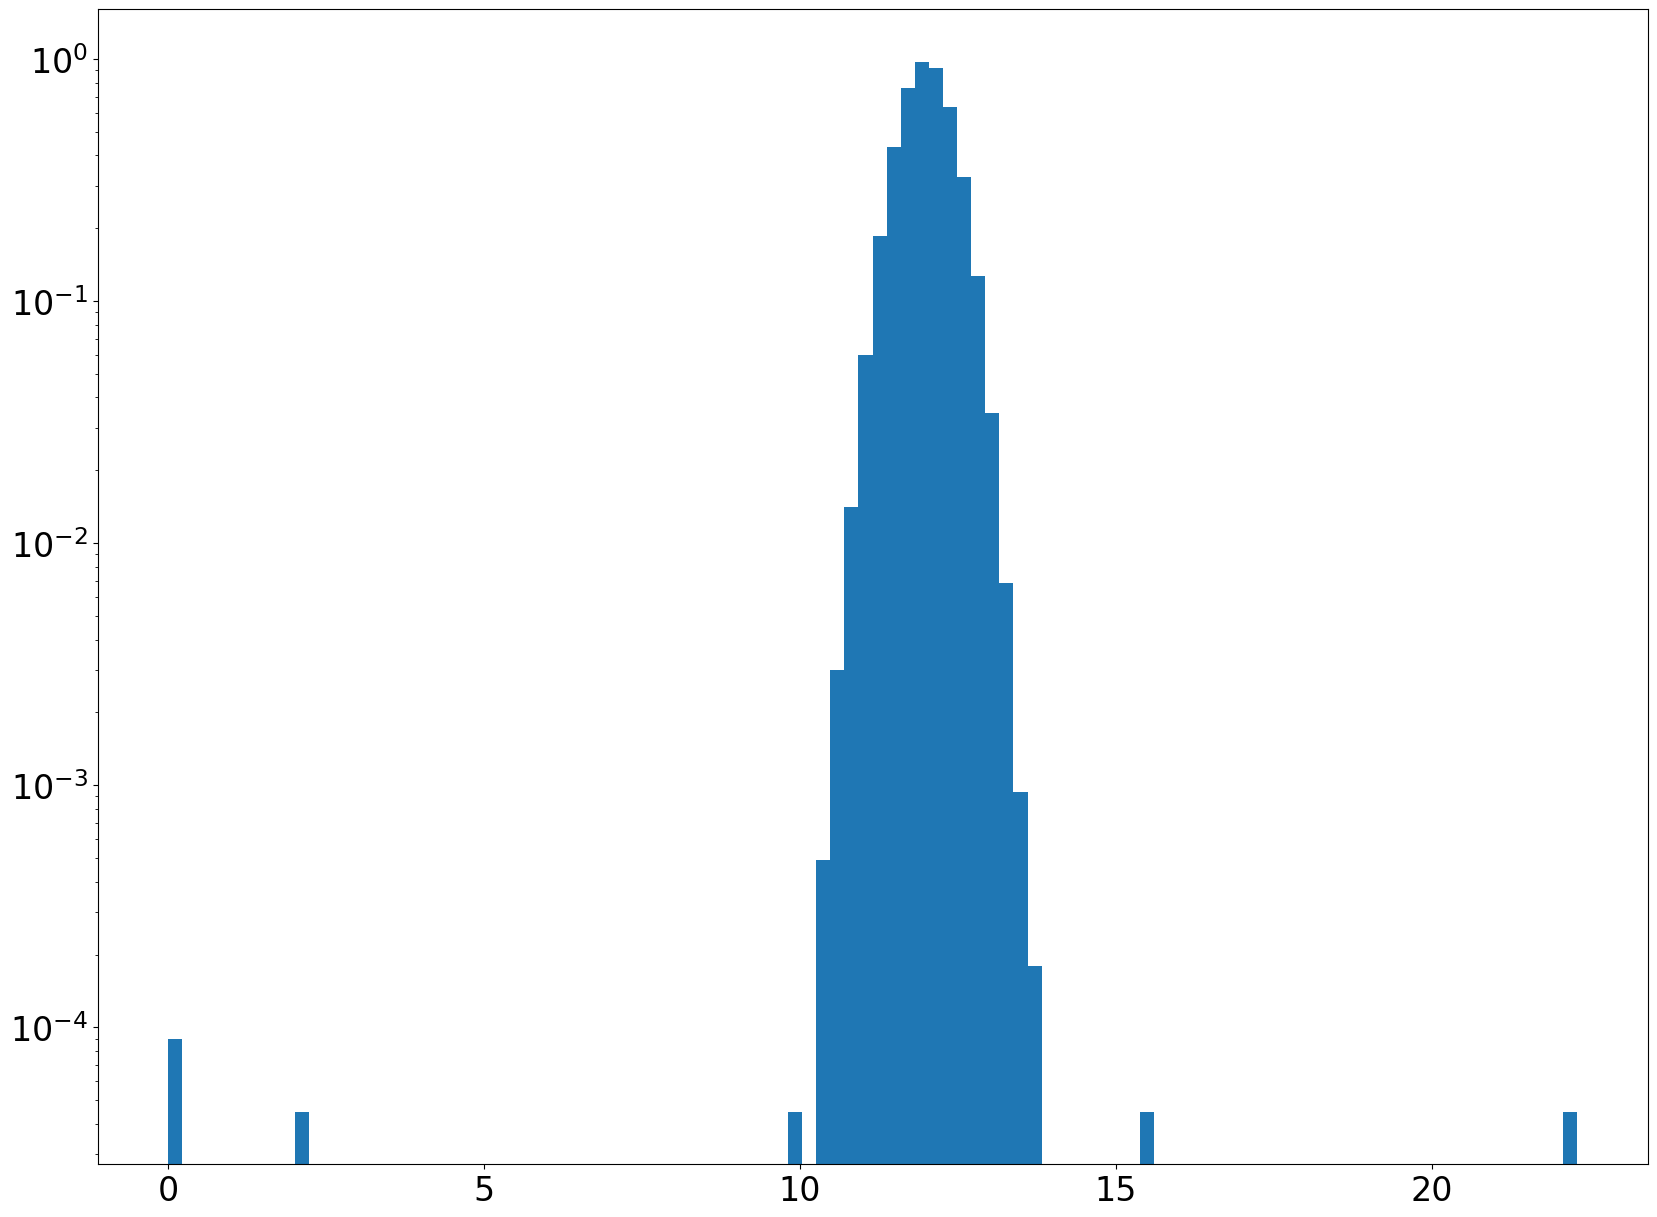

In [9]:
d = np.append(stats.norm.rvs(loc = 12., scale = 0.4, size = 100000), [10., 10.3, 2.1, 0., 0., 15.6, 22.3, 12.7])
fig, ax = plt.subplots(1, 1)
ax.hist(d,100, density=True)
plt.tick_params(labelsize = 24)
plt.yscale('log')
#x = np.linspace(4.95,5.05,1000)
#ax.plot(x,stats.norm.pdf(x,loc = 5., scale = 0.01),linewidth = 8,alpha = 0.7)
plt.show()

**A)** So our goal is to identify bad data and throw it out.

0. Start by exploring the data you have created with appropriate plots
1. State the statistical question in words. Be very clear, and describe why you have chosen this statistical question.
2. Restate your question in math. Be very clear.
3. Apply your statistical test and construct a truth table.

The idea is how often you kept the known good data (True T & Your Test Good), how often you correctly discarded bad data (Bad T & Your Test Bad), and how often mistakes were made of either omission or commission (off diagonals).

**Statistical question: What would the probability be that the background thermal fluctuation from our normal distribution produces a reading that is as or more unsual than the observed temperature reading $T$?**

**I've chosen this question because it adresses the want to reject readings of temperature that are unlikely to have occured from the thermal control system. This way, we can catch both glitches and failures caused by the system.**

**Mathematical Representation:**

**Mean of our normal distribution:** $\mu = 12$

**Sigma:** $\sigma = 0.4$

**Converting T into a z-score:** 

$Z = \frac{\vert{}T - \mu\vert{}}{\sigma} = \frac{\vert{}T - 12\vert{}}{0.4}$

**Calculating two-tailed $p$-value with Z:**

$p = 2 \cdot \left[1 - \Phi(Z)\right] = 2 \cdot \text{stats.norm.sf}(Z)$

In [15]:
# Applying test and constructing truth table
good_data = stats.norm.rvs(loc = 12.0, scale = 0.4, size = 100000)
bad_data = [10., 10.3, 2.1, 0., 0., 15.6, 22.3, 12.7]
d = np.append(good_data, bad_data)

# Truth mask
is_true_good = np.array([True] * len(good_data) + [False] * len(bad_data))

# statistical threshold
sigma = 5.0
z_score = np.abs(d - 12.0) / 0.4

# Determines if data is good and outputs True (|z| <= threshold sigma)
test_good = z_score <= sigma

# Truth table
true_T_test_good = np.sum(is_true_good & test_good)
bad_T_test_good     = np.sum(~is_true_good & test_good)  # False Positive
true_T_test_bad  = np.sum(is_true_good & ~test_good)     # False Negative
bad_T_test_bad      = np.sum(~is_true_good & ~test_good)

print(f"Known good data that was kept: {true_T_test_good}")
print(f"Bad data incorrectly kept: {bad_T_test_good}")
print(f"Good data incorrectly kept: {true_T_test_bad}")
print(f"Known bad data that was correctly discarded: {bad_T_test_bad}")

Known good data that was kept: 100000
Bad data incorrectly kept: 3
Good data incorrectly kept: 0
Known bad data that was correctly discarded: 5


**B)** How does the number of omissions, where you threw out good data, depend on the statistical threshold you chose and is it a predictable quantity?

**We see that omissions occur when the true data is fluctuating beyond our statistical threshold, $\vert{}Z\vert{} > Z_{\text{thresh}}$. It is a predictable quantity because we can calculate the probability of false omissions per measurement using the mathematical equation:**

$P_{\text{omission}} = 2 \cdot \left[1 - \Phi(Z_{\text{thresh}})\right]$.

**Since our threshold was $5\sigma$ and our sample size was $N = 100,000$ points, the number of omissions can be expected as $N \times P_{\text{omission}}$. Where $5\sigma$ yields about $\sim 0.057$ points omitted, which is a very small number that is almost $0$.**

**C)** Are there mistakes of commission (bad data getting in)? If yes, are they avoidable and how do they depend on your statistical threshold?

**Yes, there are some mistakes of commission. For example one of our bad data points 12.7 K has a $Z$-score of $\frac{\vert{}12.7 - 12.0\vert{}}{0.4} = 1.75\sigma$. And another one of our bad data points 10.3 K had a $Z$-score of $\frac{\vert{}10.3 - 12.0\vert{}}{0.4} = 4.25\sigma$. Our threshold cut-off is $5\sigma$, so both of these bad data points are within the allowed interval and pass as "good" data points when they really aren't. They aren't avoidable when basing the test on temperature values alone, because 12.7 K for example is already very close to the expected value of 12 K. The dependence on my statistical threshold is that if I were to lower the threshold down $1\sigma$ to $4\sigma$, we would be able to catch 10.3 K as a bad point but 12.7 K would be caught right inside the peak of the normal distribtuion. This would make it indistinguishable from my real good data.**

**Problem 2**

In this example we will be looking for asteroids. If we look at the alignment of stars on subsequent images, they don't perfectly align due to atmospheric and instrumental effects (even ignoring proper motion). The resulting distribution is two dimensional, and for this lab let's assume it is a 2D Gaussian with 1 arcsecond RMS. Or said another way, if I histogram how far all the (stationary) stars appear to have moved I get something like:

<>:9: SyntaxWarning: invalid escape sequence '\D'
<>:10: SyntaxWarning: invalid escape sequence '\D'
<>:9: SyntaxWarning: invalid escape sequence '\D'
<>:10: SyntaxWarning: invalid escape sequence '\D'
/tmp/ipykernel_2384/2121784878.py:9: SyntaxWarning: invalid escape sequence '\D'
  plt.ylabel("$\Delta$y arcseconds", fontsize = 18)
/tmp/ipykernel_2384/2121784878.py:10: SyntaxWarning: invalid escape sequence '\D'
  plt.xlabel("$\Delta$x arcseconds", fontsize = 18)


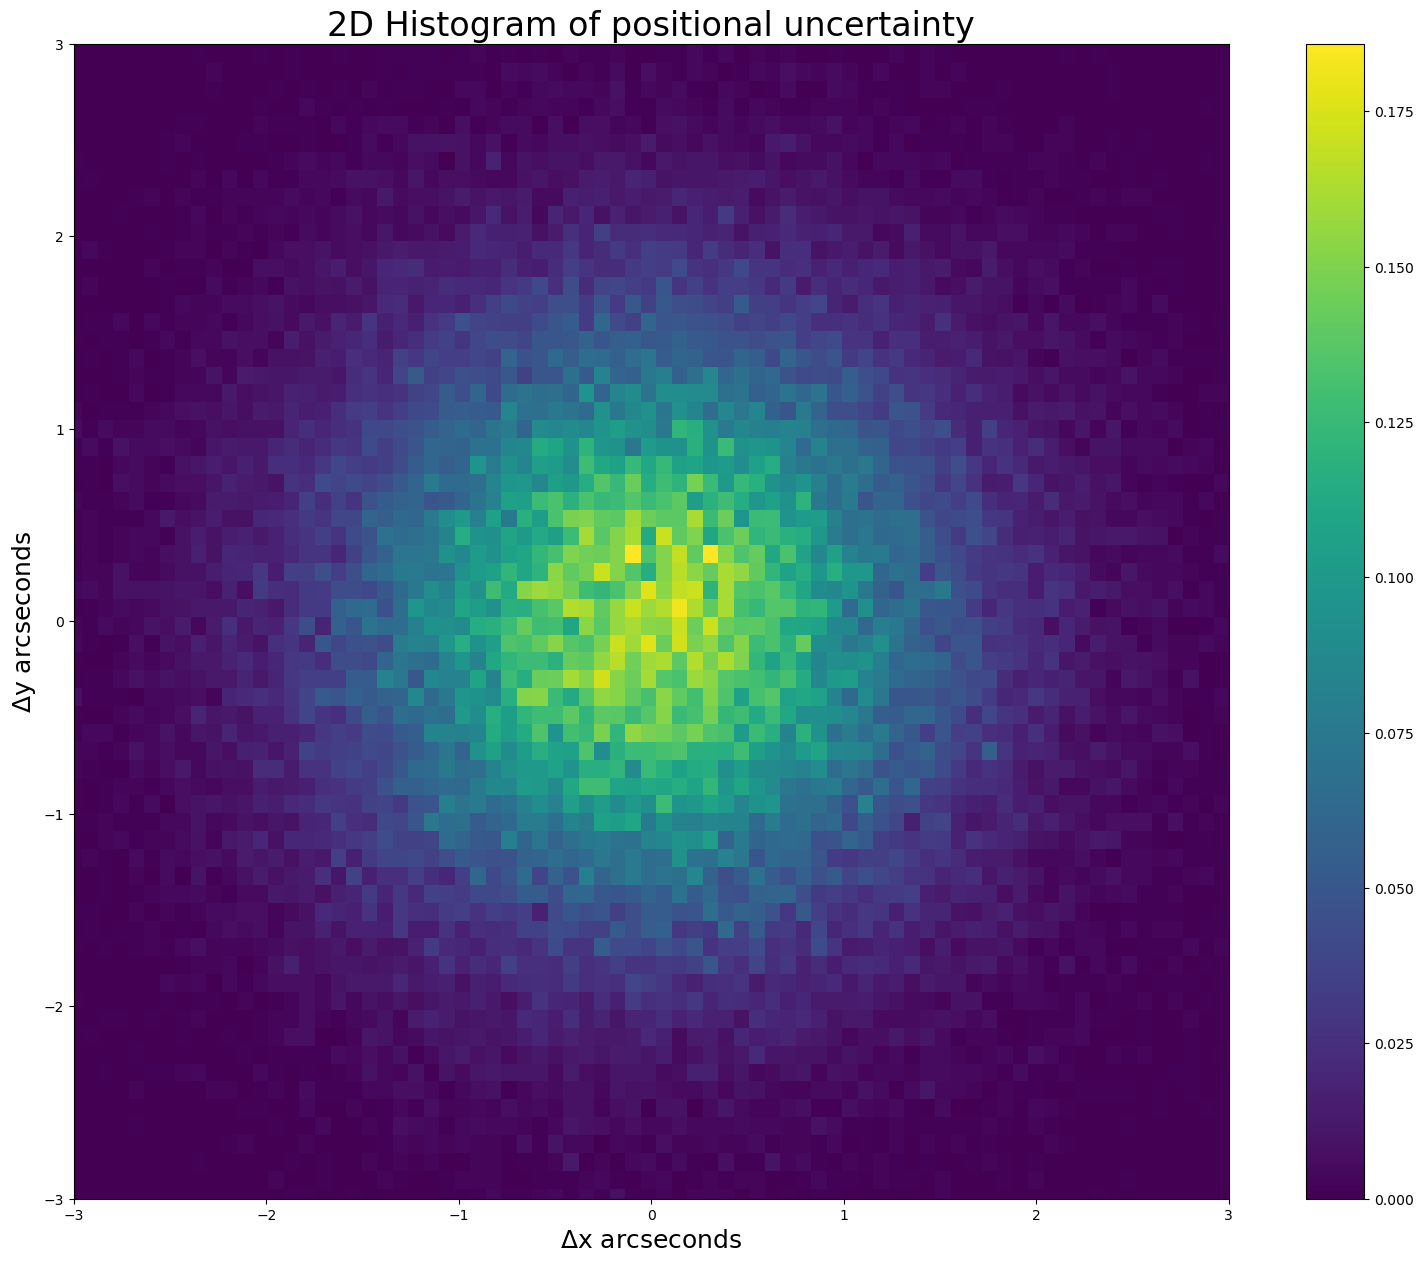

In [16]:
a = np.vstack((stats.norm.rvs( scale = 1, size = 100000), stats.norm.rvs( scale = 1, size = 100000)))
a.shape
fig, ax = plt.subplots(1, 1)
h = ax.hist2d(a[0,:],a[1,:],bins=100, density=True);
ax.set_aspect('equal', 'box')
plt.xlim([-3 , 3])
plt.ylim([-3 , 3])
plt.title("2D Histogram of positional uncertainty", fontsize = 24)
plt.ylabel("$\Delta$y arcseconds", fontsize = 18)
plt.xlabel("$\Delta$x arcseconds", fontsize = 18)
plt.colorbar(h[3], ax=ax)

If I have a potential asteroid, it will have some true movement between the images. We would like a '5 sigma' detection of movement. What is that distance in arcseconds?

**1. What is the question in words?**

Statistical question: What is the smallest apparent shift that a star can make where it can be determined as actual movement, rather than some random 2-D background noise mimicking a shift with a probability equal to or lower than a 5-sigma event in 1-D?

**2. What is the question in math? [Hint: Come up with an analytic description of your pdf(). The Blue Book may be helpful here.]**

Mathematical question: 

The radial distance $r$ is defined as $r = \sqrt{\Delta x^2 + \Delta y^2}$, where it follows a Rayleigh distribution in terms of $r$ (PDF):

$f(r;\sigma) = \frac{r}{\sigma^2} e^{-r^2 / (2\sigma^2)} \quad (r \ge 0)$

The scale parameter is $\sigma = 1$:

$f(r) = r e^{-r^2/2}$

The CDF, where the scale parameter is $\sigma = 1$ is:

$F(r) = 1 - e^{-r^2/2} \quad (r \ge 0)$

To find the probability of measuring a fluctuation of atleast a distance $r$, we use the survivial function:

$S(r) = P(R \ge r) = 1 - F(r) = e^{-r^2/2}$

So we can define: 

$P(R \ge r) = e^{-r^2 / 2} = \alpha_{5\sigma}$,

where the 5-sigma tail probability $\alpha_{5\sigma} = 2 \cdot [1 - \Phi(5)]$ for a 1-D two-tailed $5\sigma$.

**3. What distance in arcseconds represents a 5 sigma detection of motion?**

In [17]:
# Calculating the 5-sigma probability (1-D 2-tailed)
p_5sigma = 2 * stats.norm.sf(5)

# Finding radial distance r with Rayleigh distribution / survival function
# S(r) = exp(-r^2 / 2), changes to r = sqrt(-2 * ln(P))
r = np.sqrt(-2 * np.log(p_5sigma))

print(f"5-sigma 2-tailed p-value: {p_5sigma:.4e}")
print(f"Distance of 5-sigma detection of motion: {r:.4f} arcseconds")

5-sigma 2-tailed p-value: 5.7330e-07
Distance of 5-sigma detection of motion: 5.3613 arcseconds


**Problem 3**

As we discussed in class, one of the key backgrounds for gamma-ray telescopes are cosmic rays. Cosmic rays are charged particles—usually protons or electrons but can include atomic nuclei such a alpha particles (helium) or iron. Because of their charge cosmic rays spiral in the magnetic field of the galaxy. From the perspective of the Earth they appear to be coming uniformly from all directions like a high energy gas, and the direction the cosmic ray is travelling when it reaches the Earth tells us nothing about where it came from because we don't know what tortured path it has taken through the galaxy to reach us. However, at trillion electron volt energies and above, the spiral loops are fairly big and the sun and the moon will block cosmic rays. This means the sun and the moon appear as holes in the cosmic ray sky (cosmic rays from that direction are absorbed).

Assume in a moon sized patch on the sky we normally have a cosmic ray rate of 1 cosmic ray per minute (arrivals are random in time). If we can observe where the moon is for 8 hours per night (not too close to the horizon) and we observe for 15 days and see 6800 cosmic rays, what is the signficance of our moon shadow detection?

**1. What is the question in words?**

With the moon blocking out cosmic rays, what would be the probability that random fluctuations in our background with an expected count of $N = 7200$ produce a deficit as or larger than what was observed ($N \le 6800$), and what would be the equivalent sigma $\sigma$?

**2. Translate the question to math, describing both the expected background pdf() and the integral you need to do.**

Mathematical question:

We can use the Poisson distribution and set $N = 7,200$ as our lambda $\lambda$:

$P(X = k; \lambda) = \frac{\lambda^k e^{-\lambda}}{k!}$

This is because it counts the discrete, independent events that occur at a constant rate over time. Since $\lambda = 7,200$ is very large, our Poisson distribution becomes pretty well defined by a Gaussian distribution. Where the mean $\mu$ is $\mu = 7,200$ and the standard deviation $\sigma = \sqrt{7,200} \approx 84.85$. 

For our integral, we want to do a 1-tailed test on the lower tail because of the deficit that will be caused by the moon's area blocking cosmic rays:

$p\text{-value} = P(N \le 6,800) = \int_{-\infty}^{6,800} \frac{1}{\sqrt{2\pi \sigma^2}} \exp\left( -\frac{(x - \mu)^2}{2\sigma^2} \right) dx = \Phi\left( \frac{6,800 - 7,200}{\sqrt{7,200}} \right) \approx \Phi(-4.714)$

**3. Convert to sigma.**

In [18]:
# Parameters 
bg_rate = 1.0 # Cosmic rays per minute
time_min = 7200 # Minutes, 15 days * 8 hours/day * 60 minutes/hour
mu = bg_rate * time_min # 7,200 expected cosmic rays
observed = 6800 # observed cosmic rays

# Calculating Gaussian approximation
sigma = np.sqrt(mu)
zscore = (observed - mu) / sigma
p_value = stats.norm.cdf(zscore)

# Poisson Cumulative distribution function (CDF)
p_value_poisson = stats.poisson.cdf(observed, mu)

print(f"The Significance is: {abs(zscore):.3f} sigma")
print(f"The Gaussian p-value is: {p_value:.4e}")
print(f"The Poisson p-value is: {p_value_poisson:.4e}")

The Significance is: 4.714 sigma
The Gaussian p-value is: 1.2142e-06
The Poisson p-value is: 1.0133e-06
